---
**Script name:** 04_01_01_node_data_processing.ipynb

**Purpose of script:** This script is to pre-process node data in preparation to correct the corrupted timestamps. 

**Author:** Dr Katie Allan

**Date Created:** 2022-07-10

**Email:** katie.allan@sussex.ac.uk

**License:** 

---

**Notes:** Change 'path_to_folder' to appropriate folder paths.

---

## Importing libraries that are required

In [ ]:
#import libraries
import os
import pandas as pd
from pandas.api.types import is_datetime64_ns_dtype
import numpy as np
import pickle
import datetime
import re
from plotnine import (
    ggplot,
    aes,
    after_stat,
    geom_point,
    geom_line,
    geom_bar,
    geom_histogram,
    coord_flip,
    facet_wrap,
    theme_matplotlib,
    theme_set,
)

In [10]:
# Set the theme for all the plots
theme_set(theme_matplotlib())

## Functions that are used throughout the script

In [21]:
# Function to filter a DataFrame by the list of strings
def filter_dataframe(df, filter_list, variables):
    return df[df[variables].isin(filter_list)]

In [27]:
# Function to change time column to datetime64
def convert_time_column(df, variables):
    #using loc to avoid the 'SettingWithCopyWarning'
    df[variables] = pd.to_datetime(df[variables], format = '%Y-%m-%dT%H:%M:%SZ')
    return df

In [32]:
# Function to filter data into correct time
def filter_correct_time(df, variable):
    right_time = df.loc[(df[variable] >= '2020-01-01')]
    return right_time

In [33]:
# Function to filter data into incorrect time
def filter_wrong_time(df, variable):
    wrong_time = df.loc[(df[variable] < '2020-01-01')]
    return wrong_time

## Load Data

In [ ]:
# set path to raw node data
dir_path = 'path_to_folder'

In [ ]:
# list the subdirectories of node deployments
filelist = os.listdir(dir_path)
print(filelist)

In [ ]:
#test printing the full directory path of a file
print(dir_path + "/" + filelist[1])

In [14]:
# Define regular expression pattern to match filenames with numbers
folder_pattern = re.compile('\w{6}\s{1}')
file_pattern = re.compile(r'beep_\d+\.csv')

In [ ]:
#make loop to import node detection data files using regex to match file types
# create empty dictionary for dataframes and list for names
dataframes = {}

# Create loop to import files
for folder in filelist:
    #create folder name
    folder_name = folder
    
    #check folder matches node_id value
    if re.match(folder_pattern, folder_name):
        #set the full folder path
        full_path = f'{dir_path}/{folder_name}'
        print(full_path)
        
        #list all files in this directory
        beeplist = os.listdir(full_path)
        print(beeplist)
        
        #loop through each file in node folder
        for file in beeplist:
            #check file matches beep_
            if re.match(file_pattern, file):
                #set the node id from folder
                node_id = f'node_{folder_name[:6]}'
               
                #set file list without .csv
                file_id = file[:-4]
                #create file name
                file_name = f'{node_id}_{file_id}'
                print(file_name)

                #create file_path variable
                file_path = f'{full_path}/{file}'
                
                #read file into python
                df = pd.read_csv(file_path, header = [0])

                #assign file to python dictionary
                dataframes[file_name] = df

#print the key name and dataframe
#for key, dataframe in dataframes.items():
    #print(f'Dataframe for {key}:')
    #print(dataframe)

In [16]:
# check which dataframes are loaded
%whos DataFrame

Variable   Type         Data/Info
---------------------------------
df         DataFrame                         time<...>n\n[109 rows x 3 columns]


In [17]:
# print a specific dataframe
print(dataframes['node_32b6e0_beep_6'])

                       time        id  rssi
0      2017-01-01T01:01:04Z  55331961   -27
1      2017-01-01T01:01:14Z  55331961   -26
2      2017-01-01T01:01:24Z  55331961   -27
3      2017-01-01T01:01:34Z  55331961   -27
4      2017-01-01T01:01:44Z  55331961   -27
...                     ...       ...   ...
25053  2017-01-24T23:37:48Z  4B662A33  -109
25054  2017-01-24T23:37:58Z  4B662A33  -109
25055  2017-01-24T23:40:27Z  4B662AB3  -109
25056  2017-01-24T23:42:37Z  4B662A33  -110
25057  2017-01-24T23:42:39Z  66667833  -114

[25058 rows x 3 columns]


In [18]:
# print specific column
print(dataframes['node_32b6e0_beep_6']['time'])

0        2017-01-01T01:01:04Z
1        2017-01-01T01:01:14Z
2        2017-01-01T01:01:24Z
3        2017-01-01T01:01:34Z
4        2017-01-01T01:01:44Z
                 ...         
25053    2017-01-24T23:37:48Z
25054    2017-01-24T23:37:58Z
25055    2017-01-24T23:40:27Z
25056    2017-01-24T23:42:37Z
25057    2017-01-24T23:42:39Z
Name: time, Length: 25058, dtype: object


In [19]:
#print one index and length of keys
print(len(dataframes))

44


## Data processing

In [ ]:
# set list of tag id's to filter all node data by - tags which were used in the study
bat_test_tag_ids = ['55331961','4B551E4B', '78780778', '4C785261', '2D661E19', '33333433', '78341E61', '52616161', '662A6107', '614B2A61', '34332A07', '612A4C1E', '2D2D612A', '2D2A7852', '07071E19', '2D192D78', '1E4B074C', '4B662A33', '19557855', '2A615252', '33663378', '5561331E', '341E4B2A', '1978782D', '2D344B2D', '19616666', '551E3307', '34783378', '66667833', '4B616652', '4C610761', '33331E55', '612A3355', '4B2D664C']
bat_tag_ids = ['4C785261', '2D661E19', '33333433', '78341E61', '52616161', '662A6107', '614B2A61', '34332A07', '612A4C1E', '2D2D612A', '2D2A7852', '07071E19', '2D192D78', '1E4B074C', '4B662A33', '19557855', '2A615252', '33663378', '5561331E', '341E4B2A', '1978782D', '2D344B2D', '19616666', '551E3307', '34783378', '66667833', '4B616652', '4C610761', '33331E55', '612A3355', '4B2D664C']
test_tag_ids = ['55331961','4B551E4B', '78780778']

In [22]:
# print the original shape of the dataframe
[(key, df.shape) for key, df in dataframes.items()]

[('node_327d6b_beep_0', (781, 3)),
 ('node_327d6b_beep_1', (1563, 3)),
 ('node_32800c_beep_1', (862, 3)),
 ('node_32800c_beep_2', (168, 3)),
 ('node_32800c_beep_3', (76, 3)),
 ('node_328787_beep_3', (8090, 3)),
 ('node_328787_beep_4', (1871, 3)),
 ('node_3289f1_beep_1', (1760, 3)),
 ('node_3289f3_beep_1', (297, 3)),
 ('node_3289f3_beep_2', (4143, 3)),
 ('node_3289f3_beep_3', (3074, 3)),
 ('node_328f57_beep_2', (189, 3)),
 ('node_3292c8_beep_3', (9488, 3)),
 ('node_3292c8_beep_4', (1577, 3)),
 ('node_32b6e0_beep_5', (16508, 3)),
 ('node_32b6e0_beep_6', (25058, 3)),
 ('node_32b6e0_beep_7', (14499, 3)),
 ('node_3750b3_beep_4', (5104, 3)),
 ('node_3750b3_beep_5', (1914, 3)),
 ('node_3750b3_beep_3', (1153, 3)),
 ('node_376a2b_beep_2', (155, 3)),
 ('node_376a2b_beep_3', (7693, 3)),
 ('node_376a2b_beep_4', (1287, 3)),
 ('node_376adf_beep_3', (667, 3)),
 ('node_376adf_beep_4', (736, 3)),
 ('node_376adf_beep_5', (578, 3)),
 ('node_376f37_beep_2', (701, 3)),
 ('node_376f37_beep_3', (1008, 3)),
 

In [23]:
# filter the dataframes by the bat and test tag ID's
bat_test_dataframes = {key: filter_dataframe(df, bat_test_tag_ids, 'id') for key, df in dataframes.items()}

In [24]:
#print shape of new dataframes
[(key, df.shape) for key, df in bat_test_dataframes.items()]

[('node_327d6b_beep_0', (411, 3)),
 ('node_327d6b_beep_1', (1442, 3)),
 ('node_32800c_beep_1', (621, 3)),
 ('node_32800c_beep_2', (97, 3)),
 ('node_32800c_beep_3', (21, 3)),
 ('node_328787_beep_3', (7509, 3)),
 ('node_328787_beep_4', (1751, 3)),
 ('node_3289f1_beep_1', (1602, 3)),
 ('node_3289f3_beep_1', (235, 3)),
 ('node_3289f3_beep_2', (3961, 3)),
 ('node_3289f3_beep_3', (2886, 3)),
 ('node_328f57_beep_2', (141, 3)),
 ('node_3292c8_beep_3', (8930, 3)),
 ('node_3292c8_beep_4', (1447, 3)),
 ('node_32b6e0_beep_5', (14694, 3)),
 ('node_32b6e0_beep_6', (24030, 3)),
 ('node_32b6e0_beep_7', (13944, 3)),
 ('node_3750b3_beep_4', (4848, 3)),
 ('node_3750b3_beep_5', (1759, 3)),
 ('node_3750b3_beep_3', (632, 3)),
 ('node_376a2b_beep_2', (22, 3)),
 ('node_376a2b_beep_3', (7406, 3)),
 ('node_376a2b_beep_4', (1141, 3)),
 ('node_376adf_beep_3', (325, 3)),
 ('node_376adf_beep_4', (598, 3)),
 ('node_376adf_beep_5', (315, 3)),
 ('node_376f37_beep_2', (572, 3)),
 ('node_376f37_beep_3', (945, 3)),
 ('no

In [25]:
#check filter worked using loop and assertion
for key, df in bat_test_dataframes.items():
    #find unique values of the dataframe id's and save as list
    unique_tags = df['id'].unique().tolist()
    #filter unique values to only keep those that are not listed in bat_test_tag_id
    leftovers = [b for b in unique_tags if all(a not in b for a in bat_test_tag_ids)]
    
    #assert that the length of the leftovers is 0, there are no extra tag id's
    assert len(leftovers) == 0, 'Data contains other tag id values.'
print(leftovers)

[]


In [26]:
#print datatype of object
print(bat_test_dataframes['node_32b6e0_beep_6'].dtypes)

time    object
id      object
rssi     int64
dtype: object


In [ ]:
# Change the time column to datetime64
for key in bat_test_dataframes:
    #set time to datetime column
    bat_test_dataframes[key] = convert_time_column(bat_test_dataframes[key], 'time')
    #print the datatype of each key
    print(f'{key}:{bat_test_dataframes[key].dtypes}')

In [29]:
#print datatype of object to check loop worked
print(bat_test_dataframes['node_32b6e0_beep_6'].dtypes)

time    datetime64[ns]
id              object
rssi             int64
dtype: object


In [30]:
#assert statemnet to check time column is correct datatype
for key, df in bat_test_dataframes.items():
    #print key
    print(key)
    #print datatype
    print(df['time'].dtype)
    
    #assert statement check thats the first row 
    assert is_datetime64_ns_dtype(df['time']), 'Time column is not datetime format.'

node_327d6b_beep_0
datetime64[ns]
node_327d6b_beep_1
datetime64[ns]
node_32800c_beep_1
datetime64[ns]
node_32800c_beep_2
datetime64[ns]
node_32800c_beep_3
datetime64[ns]
node_328787_beep_3
datetime64[ns]
node_328787_beep_4
datetime64[ns]
node_3289f1_beep_1
datetime64[ns]
node_3289f3_beep_1
datetime64[ns]
node_3289f3_beep_2
datetime64[ns]
node_3289f3_beep_3
datetime64[ns]
node_328f57_beep_2
datetime64[ns]
node_3292c8_beep_3
datetime64[ns]
node_3292c8_beep_4
datetime64[ns]
node_32b6e0_beep_5
datetime64[ns]
node_32b6e0_beep_6
datetime64[ns]
node_32b6e0_beep_7
datetime64[ns]
node_3750b3_beep_4
datetime64[ns]
node_3750b3_beep_5
datetime64[ns]
node_3750b3_beep_3
datetime64[ns]
node_376a2b_beep_2
datetime64[ns]
node_376a2b_beep_3
datetime64[ns]
node_376a2b_beep_4
datetime64[ns]
node_376adf_beep_3
datetime64[ns]
node_376adf_beep_4
datetime64[ns]
node_376adf_beep_5
datetime64[ns]
node_376f37_beep_2
datetime64[ns]
node_376f37_beep_3
datetime64[ns]
node_376f37_beep_4
datetime64[ns]
node_377401_be

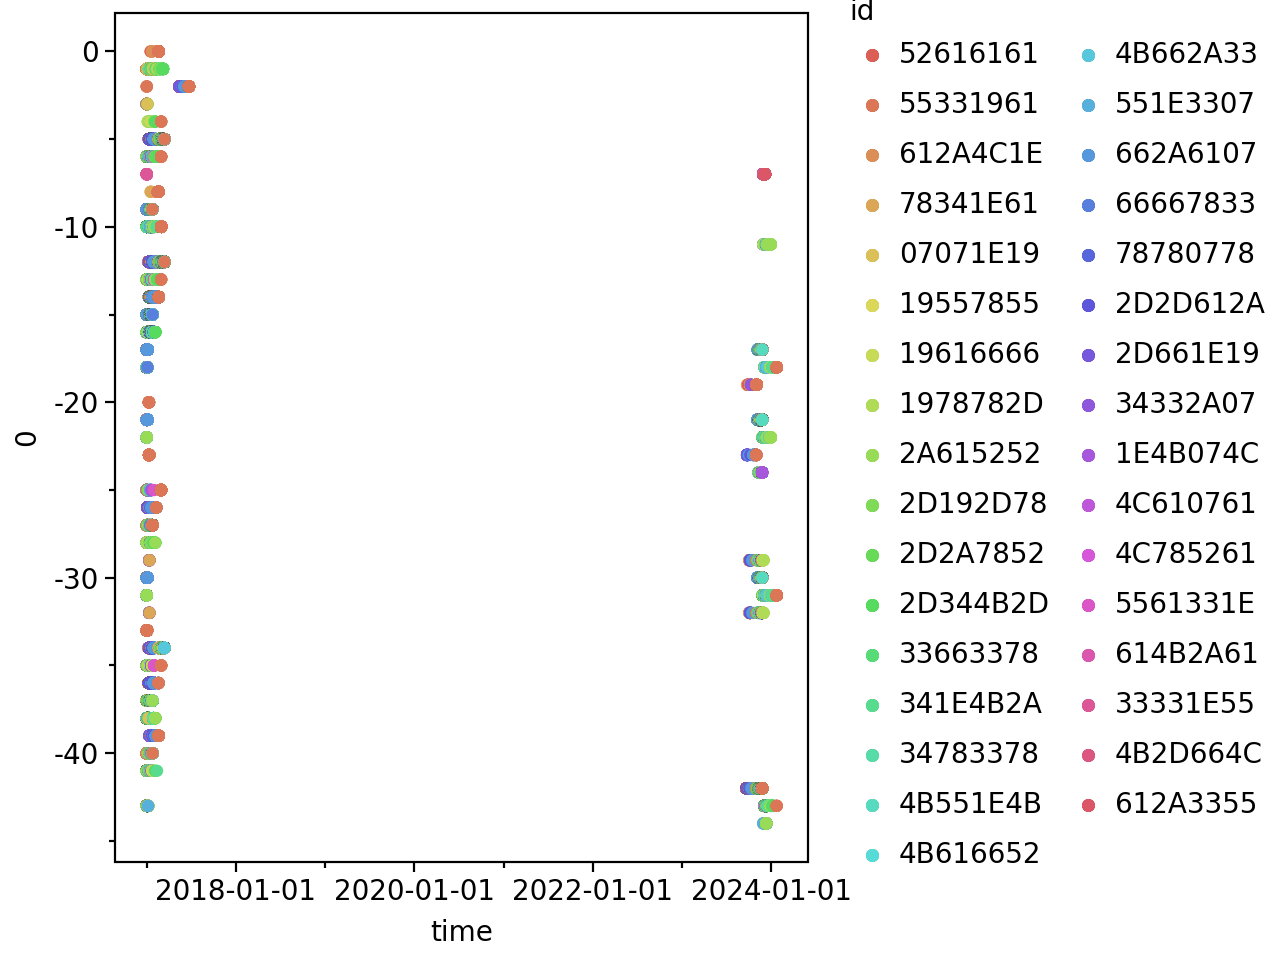

In [ ]:
#create plots of each dataframe to show datetime error
(
    ggplot(bat_test_dataframes['node_327d6b_beep_0'], aes("time", 0, colour = "id"))
    + geom_point()
    + geom_point(aes("time", -1, colour = "id"), data = bat_test_dataframes['node_327d6b_beep_1'])
    + geom_point(aes("time", -2, colour = "id"), data = bat_test_dataframes['node_32800c_beep_1'])
    + geom_point(aes("time", -3, colour = "id"), data = bat_test_dataframes['node_32800c_beep_2'])
    + geom_point(aes("time", -4, colour = "id"), data = bat_test_dataframes['node_32800c_beep_3'])
    + geom_point(aes("time", -5, colour = "id"), data = bat_test_dataframes['node_328787_beep_3'])
    + geom_point(aes("time", -6, colour = "id"), data = bat_test_dataframes['node_328787_beep_4'])
    + geom_point(aes("time", -7, colour = "id"), data = bat_test_dataframes['node_3289f1_beep_1'])
    + geom_point(aes("time", -8, colour = "id"), data = bat_test_dataframes['node_3289f3_beep_1'])
    + geom_point(aes("time", -9, colour = "id"), data = bat_test_dataframes['node_3289f3_beep_2'])
    + geom_point(aes("time", -10, colour = "id"), data = bat_test_dataframes['node_3289f3_beep_3'])
    + geom_point(aes("time", -11, colour = "id"), data = bat_test_dataframes['node_328f57_beep_2'])
    + geom_point(aes("time", -12, colour = "id"), data = bat_test_dataframes['node_3292c8_beep_3'])
    + geom_point(aes("time", -13, colour = "id"), data = bat_test_dataframes['node_3292c8_beep_4'])
    + geom_point(aes("time", -14, colour = "id"), data = bat_test_dataframes['node_32b6e0_beep_5'])
    + geom_point(aes("time", -15, colour = "id"), data = bat_test_dataframes['node_32b6e0_beep_6'])
    + geom_point(aes("time", -16, colour = "id"), data = bat_test_dataframes['node_32b6e0_beep_7'])
    + geom_point(aes("time", -17, colour = "id"), data = bat_test_dataframes['node_3750b3_beep_4'])
    + geom_point(aes("time", -18, colour = "id"), data = bat_test_dataframes['node_3750b3_beep_5'])
    + geom_point(aes("time", -19, colour = "id"), data = bat_test_dataframes['node_3750b3_beep_3'])
    + geom_point(aes("time", -20, colour = "id"), data = bat_test_dataframes['node_376a2b_beep_2'])
    + geom_point(aes("time", -21, colour = "id"), data = bat_test_dataframes['node_376a2b_beep_3'])
    + geom_point(aes("time", -22, colour = "id"), data = bat_test_dataframes['node_376a2b_beep_4'])
    + geom_point(aes("time", -23, colour = "id"), data = bat_test_dataframes['node_376adf_beep_3'])
    + geom_point(aes("time", -24, colour = "id"), data = bat_test_dataframes['node_376adf_beep_4'])
    + geom_point(aes("time", -25, colour = "id"), data = bat_test_dataframes['node_376adf_beep_5'])
    + geom_point(aes("time", -26, colour = "id"), data = bat_test_dataframes['node_376f37_beep_2'])
    + geom_point(aes("time", -27, colour = "id"), data = bat_test_dataframes['node_376f37_beep_3'])
    + geom_point(aes("time", -28, colour = "id"), data = bat_test_dataframes['node_376f37_beep_4'])
    + geom_point(aes("time", -29, colour = "id"), data = bat_test_dataframes['node_377401_beep_3'])
    + geom_point(aes("time", -30, colour = "id"), data = bat_test_dataframes['node_37792f_beep_3'])
    + geom_point(aes("time", -31, colour = "id"), data = bat_test_dataframes['node_37792f_beep_4'])
    + geom_point(aes("time", -32, colour = "id"), data = bat_test_dataframes['node_377401_beep_3'])
    + geom_point(aes("time", -33, colour = "id"), data = bat_test_dataframes['node_37792f_beep_2'])
    + geom_point(aes("time", -34, colour = "id"), data = bat_test_dataframes['node_37807e_beep_1'])
    + geom_point(aes("time", -35, colour = "id"), data = bat_test_dataframes['node_37807e_beep_2'])
    + geom_point(aes("time", -36, colour = "id"), data = bat_test_dataframes['node_3781a5_beep_1'])
    + geom_point(aes("time", -37, colour = "id"), data = bat_test_dataframes['node_3781a5_beep_2'])
    + geom_point(aes("time", -38, colour = "id"), data = bat_test_dataframes['node_3781a5_beep_3'])
    + geom_point(aes("time", -39, colour = "id"), data = bat_test_dataframes['node_37920b_beep_1'])
    + geom_point(aes("time", -40, colour = "id"), data = bat_test_dataframes['node_37920b_beep_2'])
    + geom_point(aes("time", -41, colour = "id"), data = bat_test_dataframes['node_37920b_beep_3'])
    + geom_point(aes("time", -42, colour = "id"), data = bat_test_dataframes['node_3795d0_beep_2'])
    + geom_point(aes("time", -43, colour = "id"), data = bat_test_dataframes['node_3795d0_beep_3'])
    + geom_point(aes("time", -44, colour = "id"), data = bat_test_dataframes['node_379f1a_beep_3'])
)

In [ ]:
#split data into correct (anchor) data and incorrect (corrupt) data
# create empty dictionaries
correct_dataframes = {}
incorrect_dataframes = {}

#split dataframes from dictionary into correct and incorrect time labels using loop
for key, df in bat_test_dataframes.items():
    #print the key, assign shape to variable
    original_shape = df.shape

    #filter correct time
    right_time = filter_correct_time(bat_test_dataframes[key], 'time')
    right_shape = right_time.shape

    #filter incorrect time
    wrong_time = filter_wrong_time(bat_test_dataframes[key], 'time')
    wrong_shape = wrong_time.shape

    #create variable of total shape left
    final_shape = tuple(np.add(wrong_shape, right_shape))

    #check that the wrong and right shape equal original shape, not lost any data in filter
    assert tuple(np.add(final_shape, (0, -3))) == original_shape, 'Some datapoints have been lost.'

    #assign dataframes to python dictionary
    correct_dataframes[f"{key}_correct"] = right_time
    incorrect_dataframes[f"{key}_incorrect"] = wrong_time

In [35]:
#print the key name and dataframe
for key, df in correct_dataframes.items():
    print(f'Dataframe for {key}:', df)

In [36]:
#remove any blank dataframes from dictionary
print(len(correct_dataframes))
#print(correct_dataframes.keys())
for key, df in list(correct_dataframes.items()):
    if df.shape == (0, 3):
        del correct_dataframes[key]
print(len(correct_dataframes))
#print(correct_dataframes.keys())

44
15


In [37]:
#assert statemnet to check previous filter worked
for key, df in correct_dataframes.items():
    #check there is data
    assert df.shape != (0, 3), 'This dataframe has no data.'
    
    #check the time column it still in datetime format
    assert is_datetime64_ns_dtype(df['time']), 'Time column is not datetime format.'
    #print the key
    print(f'{key} has passed all assert statements.')

node_3289f1_beep_1_correct has passed all assert statements.
node_328f57_beep_2_correct has passed all assert statements.
node_3750b3_beep_4_correct has passed all assert statements.
node_3750b3_beep_5_correct has passed all assert statements.
node_3750b3_beep_3_correct has passed all assert statements.
node_376a2b_beep_3_correct has passed all assert statements.
node_376a2b_beep_4_correct has passed all assert statements.
node_376adf_beep_3_correct has passed all assert statements.
node_376adf_beep_4_correct has passed all assert statements.
node_377401_beep_3_correct has passed all assert statements.
node_37792f_beep_3_correct has passed all assert statements.
node_37792f_beep_4_correct has passed all assert statements.
node_3795d0_beep_2_correct has passed all assert statements.
node_3795d0_beep_3_correct has passed all assert statements.
node_379f1a_beep_3_correct has passed all assert statements.


In [38]:
#create plots of each dataframe
for key, df in correct_dataframes.items():
    p = ggplot(df, aes("time", "rssi")) + geom_point(aes(color = "id"))
    p.show()

In [39]:
#print shape of remaining data
[(key, df.shape) for key, df in correct_dataframes.items()]

[('node_3289f1_beep_1_correct', (1582, 3)),
 ('node_328f57_beep_2_correct', (141, 3)),
 ('node_3750b3_beep_4_correct', (4147, 3)),
 ('node_3750b3_beep_5_correct', (1249, 3)),
 ('node_3750b3_beep_3_correct', (632, 3)),
 ('node_376a2b_beep_3_correct', (5573, 3)),
 ('node_376a2b_beep_4_correct', (1046, 3)),
 ('node_376adf_beep_3_correct', (87, 3)),
 ('node_376adf_beep_4_correct', (598, 3)),
 ('node_377401_beep_3_correct', (1659, 3)),
 ('node_37792f_beep_3_correct', (4772, 3)),
 ('node_37792f_beep_4_correct', (1301, 3)),
 ('node_3795d0_beep_2_correct', (8508, 3)),
 ('node_3795d0_beep_3_correct', (1435, 3)),
 ('node_379f1a_beep_3_correct', (73, 3))]

In [40]:
#print the key name and dataframe
#for key, df in incorrect_dataframes.items():
#    print(f'Dataframe for {key}:', df)

In [41]:
#remove any dataframes with no bat detections from dictionary
print(len(incorrect_dataframes))
#print(incorrect_dataframes.keys())
for key, df in list(incorrect_dataframes.items()):
    x = filter_dataframe(df, bat_tag_ids, 'id')
    unique_tags = x['id'].unique().tolist()
    
    if df.shape == (0, 3) or unique_tags == 0:
        del incorrect_dataframes[key]
print(len(incorrect_dataframes))
#print(incorrect_dataframes.keys())

44
39


In [42]:
#assert statemnet to check previous filter worked
for key, df in incorrect_dataframes.items():    
    #find unique values of the dataframe id's and save as list
    unique_tags = df['id'].unique().tolist()
    #filter unique values to only keep those that are not listed in bat_test_tag_id
    leftovers = [b for b in unique_tags if all(a not in b for a in bat_test_tag_ids)]
    
    #assert that the length of the leftovers is 0, there are no extra tag id's
    assert len(leftovers) == 0, 'Data contains other tag id values.'
    
    #check there is data
    assert df.shape != (0, 3), 'This dataframe has no data.'
    
    #check the time column it still in datetime format
    assert is_datetime64_ns_dtype(df['time']), 'Time column is not datetime format.'
    #print the key
    print(f'{key} has passed all assert statements.')

node_327d6b_beep_0_incorrect has passed all assert statements.
node_327d6b_beep_1_incorrect has passed all assert statements.
node_32800c_beep_1_incorrect has passed all assert statements.
node_32800c_beep_2_incorrect has passed all assert statements.
node_32800c_beep_3_incorrect has passed all assert statements.
node_328787_beep_3_incorrect has passed all assert statements.
node_328787_beep_4_incorrect has passed all assert statements.
node_3289f1_beep_1_incorrect has passed all assert statements.
node_3289f3_beep_1_incorrect has passed all assert statements.
node_3289f3_beep_2_incorrect has passed all assert statements.
node_3289f3_beep_3_incorrect has passed all assert statements.
node_3292c8_beep_3_incorrect has passed all assert statements.
node_3292c8_beep_4_incorrect has passed all assert statements.
node_32b6e0_beep_5_incorrect has passed all assert statements.
node_32b6e0_beep_6_incorrect has passed all assert statements.
node_32b6e0_beep_7_incorrect has passed all assert stat

In [43]:
#create plots of each dataframe
for key, df in incorrect_dataframes.items():
    p = ggplot(df, aes("time", "rssi")) + geom_point(aes(color = "id"))
    p.show()

In [44]:
[(key, df.shape) for key, df in incorrect_dataframes.items()]

[('node_327d6b_beep_0_incorrect', (411, 3)),
 ('node_327d6b_beep_1_incorrect', (1442, 3)),
 ('node_32800c_beep_1_incorrect', (621, 3)),
 ('node_32800c_beep_2_incorrect', (97, 3)),
 ('node_32800c_beep_3_incorrect', (21, 3)),
 ('node_328787_beep_3_incorrect', (7509, 3)),
 ('node_328787_beep_4_incorrect', (1751, 3)),
 ('node_3289f1_beep_1_incorrect', (20, 3)),
 ('node_3289f3_beep_1_incorrect', (235, 3)),
 ('node_3289f3_beep_2_incorrect', (3961, 3)),
 ('node_3289f3_beep_3_incorrect', (2886, 3)),
 ('node_3292c8_beep_3_incorrect', (8930, 3)),
 ('node_3292c8_beep_4_incorrect', (1447, 3)),
 ('node_32b6e0_beep_5_incorrect', (14694, 3)),
 ('node_32b6e0_beep_6_incorrect', (24030, 3)),
 ('node_32b6e0_beep_7_incorrect', (13944, 3)),
 ('node_3750b3_beep_4_incorrect', (701, 3)),
 ('node_3750b3_beep_5_incorrect', (510, 3)),
 ('node_376a2b_beep_2_incorrect', (22, 3)),
 ('node_376a2b_beep_3_incorrect', (1833, 3)),
 ('node_376a2b_beep_4_incorrect', (95, 3)),
 ('node_376adf_beep_3_incorrect', (238, 3)),
 

## Export data

In [ ]:
# Store data (serialize)
with open('output/correct_node_data.pickle', 'wb') as handle:
    pickle.dump(correct_dataframes, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [ ]:
# Store data (serialize)
with open('output/incorrect_node_data.pickle', 'wb') as handle:
    pickle.dump(incorrect_dataframes, handle, protocol=pickle.HIGHEST_PROTOCOL)